# Proyecto 1 · Variante A — Parejas 1 y 2: KNN base y PCA + KNN

## Alcance de esta entrega

Este notebook desarrolla los bloques de **pareja 1 y pareja 2**: carga y caracterización de `load_digits()`, normalización, partición estratificada desarrollo/prueba, persistencia de índices/folds, evaluación del KNN base y comparación con 12 pipelines PCA + KNN sobre exactamente los mismos folds. Se reportan métricas train/validación, dimensiones reales retenidas, tiempos y diferencias pareadas.

La pregunta experimental integrada es si PCA puede reducir la dimensión y el costo de predicción de KNN conservando su F1 macro. Las 64 intensidades de una imagen 8×8 son la representación inicial; parte de esa dimensión puede ser redundante o poco informativa, hipótesis que pareja 2 evaluará sin asumir que PCA necesariamente mejora el clasificador.

La prueba se mantiene reservada: aquí **no se ajusta, compara ni selecciona** ningún modelo usando sus predicciones. La evaluación final en test corresponde a pareja 3. La comparación PCA+KNN y las diferencias pareadas completas se incorporan cuando pareja 2 produzca sus resultados sobre estos mismos folds.

> Alcance estadístico: análisis descriptivo. Las medias y desviaciones estándar no constituyen una prueba de hipótesis ni evidencian significancia, equivalencia o superioridad general.

In [13]:
from pathlib import Path
import json
import math
import platform
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Buscar la raíz desde cwd permite ejecutar el notebook desde la raíz o una subcarpeta.
PROJECT_RELATIVE_PATH = Path("practicas") / "p_03"
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / PROJECT_RELATIVE_PATH / "readme.md").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Ejecuta el notebook desde una carpeta dentro del repositorio."
    )

PROJECT_DIR = PROJECT_ROOT / PROJECT_RELATIVE_PATH
REPORT_DIR = PROJECT_DIR / "report"
PLOTS_DIR = REPORT_DIR / "plots"
RESULTS_DIR = PROJECT_DIR / "results" / "pareja_1"
PAIR2_RESULTS_DIR = PROJECT_DIR / "results" / "pareja_2"
for output_dir in (REPORT_DIR, PLOTS_DIR, RESULTS_DIR, PAIR2_RESULTS_DIR):
    output_dir.mkdir(parents=True, exist_ok=True)

# Parámetros fijados por el protocolo; no se optimizan mirando el conjunto de prueba.
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
N_REPEATS = 3
K_VALUES = (1, 3, 5, 7)
PIXEL_INTENSITY_MAX = 16.0  # Máximo definido por la escala conocida de load_digits: [0, 16].
N_TIMING_MEASUREMENTS = 5
SELECTION_TOLERANCE = 0.005
PCA_VARIANCE_TARGETS = (0.80, 0.90, 0.95)

# Estética clara para que etiquetas, rejilla y colores sigan siendo legibles al proyectar.
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("colorblind")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 200,
        "axes.titleweight": "bold",
        "axes.labelcolor": "#263238",
        "text.color": "#263238",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

print(f"Python: {platform.python_version()}")
print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print(f"Directorio de trabajo: {Path.cwd()}")
print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Resultados de pareja 1: {RESULTS_DIR}")

Python: 3.13.15
scikit-learn: 1.9.0
numpy: 2.5.1
pandas: 3.0.5
matplotlib: 3.11.0
seaborn: 0.13.2
Directorio de trabajo: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/code
Raíz del proyecto: /home/ldan/Documents/0_uni/5to_sem/ml_team
Resultados de pareja 1: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1


## 1. Datos, atributos y escala de los píxeles

`load_digits()` contiene imágenes en escala de grises de **8 × 8** píxeles. Al aplanar cada imagen se obtiene un vector de **64 atributos**, uno por píxel, y la etiqueta es un dígito entre 0 y 9. El código consulta las dimensiones, tipos y rangos reales en ejecución; no copia ejemplos ni filas a mano.

La intensidad observada está en el rango conocido `[0, 16]`. Se aplica la transformación fija

$$
 x_{ij}^{(norm)} = \frac{x_{ij}}{16},
$$

donde `i` identifica una imagen y `j` uno de sus píxeles. Así cada atributo queda en `[0, 1]`. El divisor es una propiedad conocida de la escala del conjunto, no un parámetro estimado con los datos; no se ajusta un escalador usando validación o prueba. La división por una constante positiva preserva el orden relativo de las intensidades y expresa las distancias en una escala común.

La cuadrícula de ejemplos muestra una imagen por clase para relacionar los 64 valores con el problema de clasificación. El gráfico de conteos es una comprobación descriptiva de la distribución de clases.

X_raw: dimensiones=(1797, 64), tipo=float64, rango=[0.0, 16.0]
X normalizada: dimensiones=(1797, 64), tipo=float64, rango=[0.000, 1.000]
y: dimensiones=(1797,), tipo=int64, clases=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
images: dimensiones=(1797, 8, 8), tipo=float64
Número de observaciones: 1,797; atributos por observación: 64


,dígito,n,proporción
0,0,178,9.9%
1,1,182,10.1%
2,2,177,9.8%
3,3,183,10.2%
4,4,181,10.1%
5,5,182,10.1%
6,6,181,10.1%
7,7,179,10.0%
8,8,174,9.7%
9,9,180,10.0%


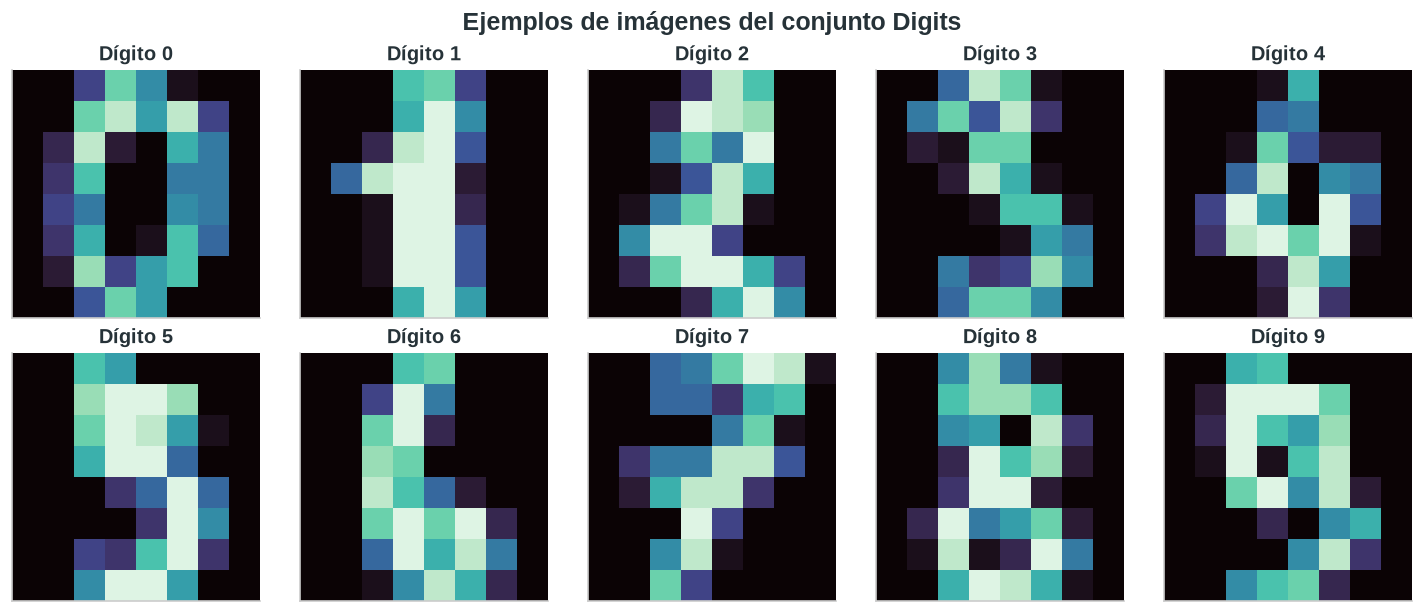

In [14]:
digits = load_digits()
X_raw = np.asarray(digits.data)
y = np.asarray(digits.target)
images = np.asarray(digits.images)

# Validar que la estructura del dataset corresponde a imágenes 8x8 aplanadas.
if X_raw.ndim != 2 or images.ndim != 3 or images.shape[1:] != (8, 8):
    raise ValueError(f"Estructura inesperada: data={X_raw.shape}, images={images.shape}")
if X_raw.shape[0] != y.shape[0] or X_raw.shape[0] != images.shape[0]:
    raise ValueError("El número de imágenes, vectores y etiquetas no coincide.")
if float(np.min(X_raw)) < 0 or float(np.max(X_raw)) > PIXEL_INTENSITY_MAX:
    raise ValueError("Las intensidades no cumplen el rango esperado [0, 16].")

# Normalización determinista con la escala fija documentada, sin estimar parámetros.
X = X_raw.astype(np.float64, copy=False) / PIXEL_INTENSITY_MAX
class_values, class_counts = np.unique(y, return_counts=True)

print(f"X_raw: dimensiones={X_raw.shape}, tipo={X_raw.dtype}, rango=[{X_raw.min()}, {X_raw.max()}]")
print(f"X normalizada: dimensiones={X.shape}, tipo={X.dtype}, rango=[{X.min():.3f}, {X.max():.3f}]")
print(f"y: dimensiones={y.shape}, tipo={y.dtype}, clases={class_values.tolist()}")
print(f"images: dimensiones={images.shape}, tipo={images.dtype}")
print(f"Número de observaciones: {X.shape[0]:,}; atributos por observación: {X.shape[1]}")

display(
    pd.DataFrame(
        {
            "dígito": class_values,
            "n": class_counts,
            "proporción": class_counts / class_counts.sum(),
        }
    ).style.format({"proporción": "{:.1%}"})
)

# Una observación representativa por clase: la primera que aparece en el dataset.
fig, axes = plt.subplots(2, 5, figsize=(12, 5), constrained_layout=True)
for ax, digit in zip(axes.flat, class_values):
    sample_position = int(np.flatnonzero(y == digit)[0])
    ax.imshow(images[sample_position], cmap="mako", vmin=0, vmax=PIXEL_INTENSITY_MAX)
    ax.set_title(f"Dígito {digit}")
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Ejemplos de imágenes del conjunto Digits", fontsize=15, fontweight="bold")
fig.savefig(PLOTS_DIR / "digits_ejemplos.png", bbox_inches="tight")
plt.show()

## 2. Partición desarrollo/prueba y validación cruzada

Se reserva una partición estratificada del 20 % como **prueba final** y el 80 % restante como desarrollo. Para mantener los índices originales, primero se separan posiciones de `X` y `y` con `train_test_split`; se usa `stratify=y` para conservar aproximadamente la proporción de las diez clases en ambas partes.

En desarrollo se aplica `RepeatedStratifiedKFold` con 5 pliegues y 3 repeticiones: cada observación de desarrollo aparece una vez en validación por repetición, para un total de $5\times3=15$ evaluaciones. La semilla raíz 42 controla el generador repetido completo. Los índices concretos de cada pliegue se guardan, y son la referencia exacta para que pareja 2 evalúe PCA+KNN sin regenerar divisiones.

En cada fold, el modelo se ajusta solo con `X_train_fold`; las métricas de validación solo se calculan sobre `X_validation_fold`. El conjunto de prueba permanece fuera de la selección. Los tamaños esperados se calculan desde el tamaño real del dataset (incluyendo el redondeo de `test_size`), y se imprimen dimensiones y conteos por clase para comprobar la partición.

X desarrollo: dimensiones=(1437, 64), tipo=float64
X prueba reservada: dimensiones=(360, 64), tipo=float64
y desarrollo: dimensiones=(1437,), tipo=int64
y prueba reservada: dimensiones=(360,), tipo=int64
Observaciones: total=1,797; desarrollo=1,437; prueba=360
Índices y folds guardados en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/indices.json


,dígito,Desarrollo,Prueba reservada
0,0,142,36
1,1,146,36
2,2,142,35
3,3,146,37
4,4,145,36
5,5,145,37
6,6,145,36
7,7,143,36
8,8,139,35
9,9,144,36


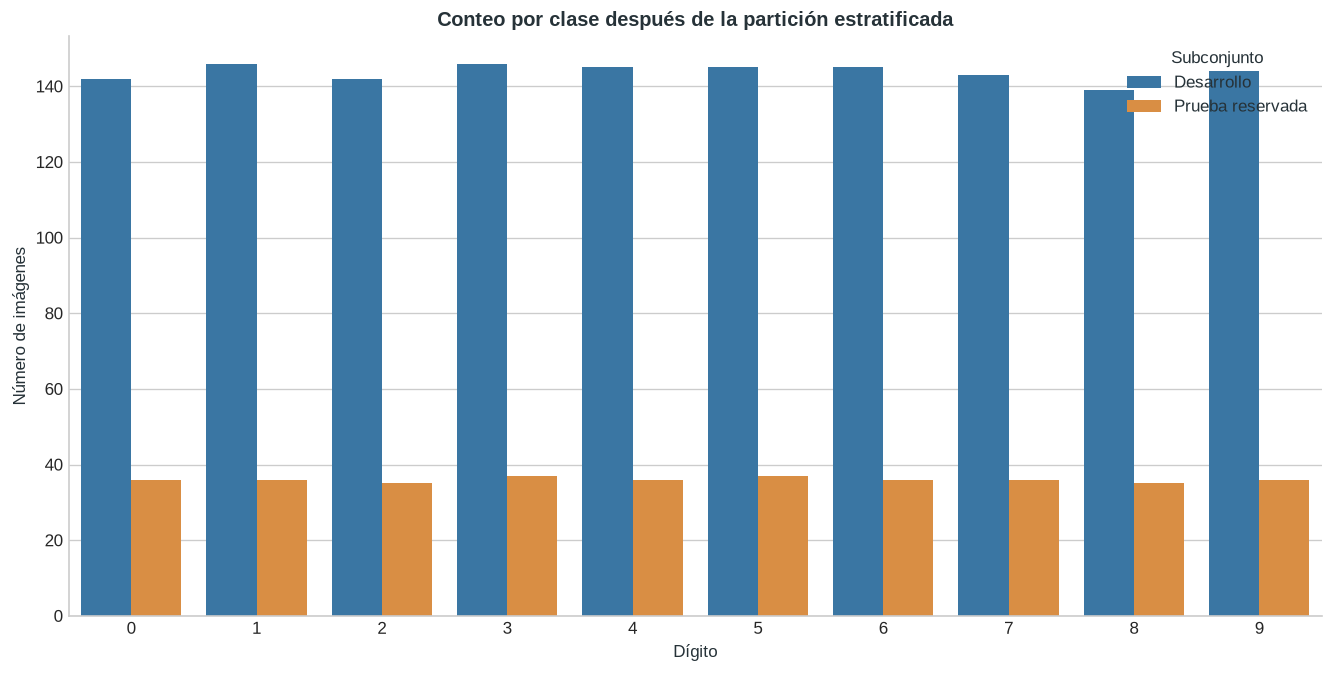

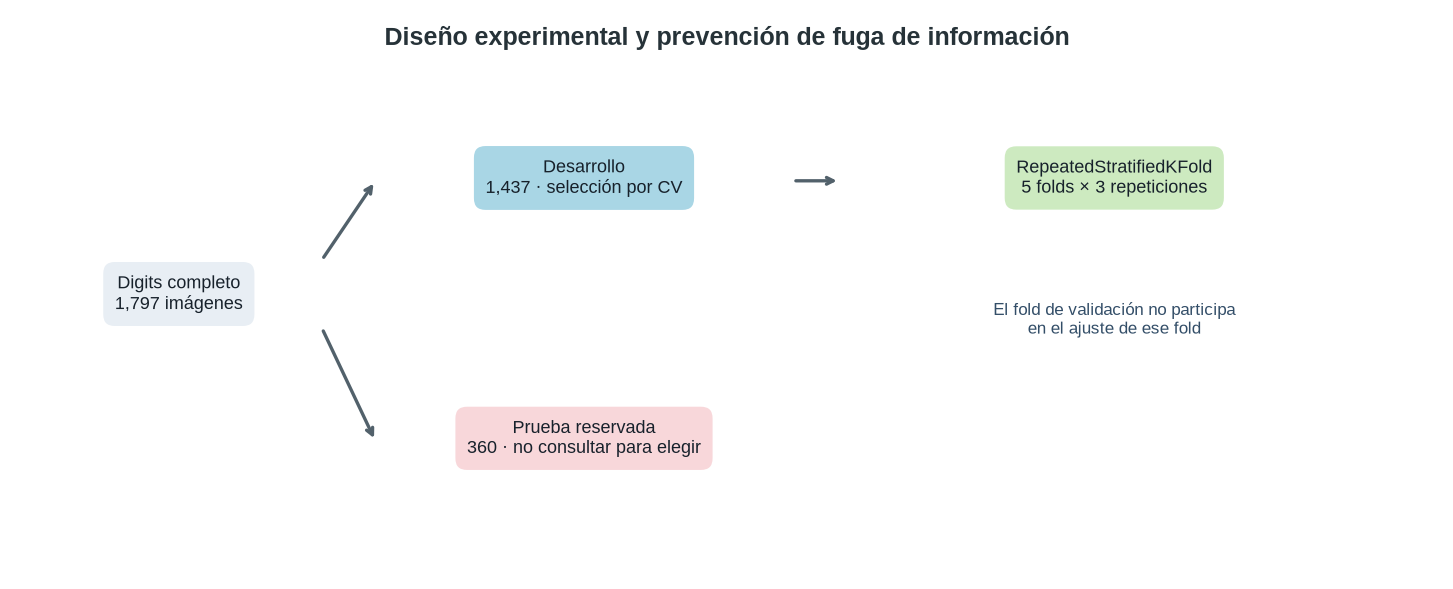

In [15]:
sample_indices = np.arange(y.size)
development_indices, test_indices = train_test_split(
    sample_indices,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)
X_development, y_development = X[development_indices], y[development_indices]
X_test_reserved, y_test_reserved = X[test_indices], y[test_indices]

expected_test_size = math.ceil(y.size * TEST_SIZE)
if test_indices.size != expected_test_size:
    raise AssertionError(
        f"Tamaño de prueba inesperado: {test_indices.size}; esperado por el protocolo: {expected_test_size}."
    )
if development_indices.size + test_indices.size != y.size:
    raise AssertionError("La partición no conserva todas las observaciones.")

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE,
)
cv_splits = list(cv.split(X_development, y_development))
if len(cv_splits) != N_SPLITS * N_REPEATS:
    raise AssertionError("La validación no produjo el número esperado de folds.")

fold_records = []
for fold_number, (train_positions, validation_positions) in enumerate(cv_splits):
    repetition = fold_number // N_SPLITS + 1
    fold_in_repetition = fold_number % N_SPLITS + 1
    fold_records.append(
        {
            "fold_id": f"rep-{repetition}-fold-{fold_in_repetition}",
            "repetition": repetition,
            "fold_in_repetition": fold_in_repetition,
            "train_development_positions": train_positions.tolist(),
            "validation_development_positions": validation_positions.tolist(),
            "train_sample_indices": development_indices[train_positions].tolist(),
            "validation_sample_indices": development_indices[validation_positions].tolist(),
        }
    )

indices_artifact = {
    "dataset": "sklearn.datasets.load_digits",
    "dataset_observations": int(y.size),
    "protocol": {
        "test_size": TEST_SIZE,
        "stratified": True,
        "random_state": RANDOM_STATE,
        "cv_class": "RepeatedStratifiedKFold",
        "n_splits": N_SPLITS,
        "n_repeats": N_REPEATS,
        "cv_random_state": RANDOM_STATE,
        "repetition_seed_records": [
            {"repetition": repetition, "root_random_state": RANDOM_STATE, "independent_seed": False}
            for repetition in range(1, N_REPEATS + 1)
        ],
        "seed_note": (
            "La semilla 42 inicializa el generador de RepeatedStratifiedKFold para las tres repeticiones; "
            "los índices realizados se persisten abajo como referencia exacta."
        ),
    },
    "development_sample_indices": development_indices.tolist(),
    "test_sample_indices": test_indices.tolist(),
    "folds": fold_records,
}
INDICES_PATH = RESULTS_DIR / "indices.json"
INDICES_PATH.write_text(json.dumps(indices_artifact, indent=2), encoding="utf-8")

print(f"X desarrollo: dimensiones={X_development.shape}, tipo={X_development.dtype}")
print(f"X prueba reservada: dimensiones={X_test_reserved.shape}, tipo={X_test_reserved.dtype}")
print(f"y desarrollo: dimensiones={y_development.shape}, tipo={y_development.dtype}")
print(f"y prueba reservada: dimensiones={y_test_reserved.shape}, tipo={y_test_reserved.dtype}")
print(f"Observaciones: total={y.size:,}; desarrollo={y_development.size:,}; prueba={y_test_reserved.size:,}")
print(f"Índices y folds guardados en: {INDICES_PATH}")

# Verificar y documentar los conteos de clase; la prueba solo se describe, no se usa para elegir.
class_distribution = pd.DataFrame({"dígito": class_values})
for partition_name, labels in (("Desarrollo", y_development), ("Prueba reservada", y_test_reserved)):
    counts = pd.Series(labels).value_counts().reindex(class_values, fill_value=0)
    class_distribution[partition_name] = counts.to_numpy()
display(class_distribution)

class_distribution_long = class_distribution.melt(
    id_vars="dígito", var_name="Partición", value_name="Observaciones"
)
fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
sns.barplot(
    data=class_distribution_long,
    x="dígito",
    y="Observaciones",
    hue="Partición",
    palette=["#2878B5", "#F28E2B"],
    ax=ax,
)
ax.set(title="Conteo por clase después de la partición estratificada", xlabel="Dígito", ylabel="Número de imágenes")
ax.legend(title="Subconjunto", frameon=False)
fig.savefig(PLOTS_DIR / "conteo_clases_split.png", bbox_inches="tight")
plt.show()

# Diagrama del protocolo, no una evaluación adicional: prueba queda aislada de la CV.
fig, ax = plt.subplots(figsize=(12, 4.8), constrained_layout=True)
ax.set_xlim(0, 12)
ax.set_ylim(0, 5)
ax.axis("off")

def add_box(x, y, width, height, text, color, fontsize=11):
    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        color="#17212B",
        bbox={"boxstyle": "round,pad=0.7", "facecolor": color, "edgecolor": "#FFFFFF", "linewidth": 1.5},
    )

add_box(0.3, 1.8, 2.2, 1.4, f"Digits completo\n{y.size:,} imágenes", "#E8EEF4")
add_box(3.2, 2.9, 3.2, 1.25, f"Desarrollo\n{y_development.size:,} · selección por CV", "#A9D6E5")
add_box(7.1, 2.9, 4.3, 1.25, f"RepeatedStratifiedKFold\n{N_SPLITS} folds × {N_REPEATS} repeticiones", "#CDEAC0")
add_box(3.2, 0.65, 3.2, 1.15, f"Prueba reservada\n{y_test_reserved.size:,} · no consultar para elegir", "#F8D7DA")
ax.annotate("", xy=(3.05, 3.5), xytext=(2.6, 2.8), arrowprops={"arrowstyle": "->", "lw": 2, "color": "#52616B"})
ax.annotate("", xy=(3.05, 1.2), xytext=(2.6, 2.2), arrowprops={"arrowstyle": "->", "lw": 2, "color": "#52616B"})
ax.annotate("", xy=(6.95, 3.5), xytext=(6.55, 3.5), arrowprops={"arrowstyle": "->", "lw": 2, "color": "#52616B"})
ax.text(6, 4.7, "Diseño experimental y prevención de fuga de información", ha="center", fontsize=15, fontweight="bold")
ax.text(9.25, 2.15, "El fold de validación no participa\nen el ajuste de ese fold", ha="center", fontsize=10, color="#334E68")
fig.savefig(PLOTS_DIR / "flujo_validacion.png", bbox_inches="tight")
plt.show()

## 3. Algoritmo base: K-Nearest Neighbors

KNN es un método basado en instancias: para una observación nueva $x$, localiza los $k$ puntos de entrenamiento más cercanos y asigna la clase más votada. La distancia euclidiana usada aquí es

$$
 d(x,z)=\sqrt{\sum_{j=1}^{D}(x_j-z_j)^2},
$$

donde $D=64$ es el número de píxeles. `metric="minkowski", p=2` representa esta distancia; `weights="uniform"` asigna un voto a cada vecino; `algorithm="brute"` calcula las distancias de forma uniforme y es la opción exigida para que pareja 2 compare con la misma estrategia computacional. Se prueban los cuatro valores `k ∈ {1, 3, 5, 7}` indicados por el protocolo.

Para cada fold se calcula F1 macro y exactitud, tanto sobre el propio entrenamiento como sobre validación. F1 macro da el mismo peso a cada clase:

$$
F1_c=\frac{2\,P_cR_c}{P_c+R_c},\qquad
F1_{macro}=\frac{1}{C}\sum_{c=1}^{C}F1_c,
$$

con precisión $P_c=TP_c/(TP_c+FP_c)$, recall $R_c=TP_c/(TP_c+FN_c)$ y $C=10$ clases. La exactitud es el número de predicciones correctas dividido por el total. La métrica principal es F1 macro; exactitud es secundaria.

El tiempo de inferencia se mide solo en el bloque de validación: una predicción de calentamiento descartada y luego cinco mediciones con `perf_counter`; la **mediana** de esas cinco es el tiempo de ese fold. Las mediciones repetidas de cronómetro no son folds independientes. El ajuste y el tiempo de entrenamiento no forman parte de esta medida. F1 de entrenamiento puede ser optimista (especialmente con `k=1`, porque cada punto es su propio vecino al predecir el train), por lo que la comparación de generalización se basa en validación.

In [16]:
def measure_prediction_time_ms(estimator, X_batch, n_measurements=N_TIMING_MEASUREMENTS):
    """Retorna las mediciones de predict en ms, tras una llamada de calentamiento descartada."""
    estimator.predict(X_batch)  # Calentamiento: no se incluye en el resumen del fold.
    measured_ms = []
    for _ in range(n_measurements):
        start = time.perf_counter()
        estimator.predict(X_batch)
        measured_ms.append((time.perf_counter() - start) * 1_000)
    return measured_ms

fold_metric_rows = []
for fold_number, ((train_positions, validation_positions), fold_info) in enumerate(
    zip(cv_splits, fold_records), start=1
):
    X_train_fold = X_development[train_positions]
    y_train_fold = y_development[train_positions]
    X_validation_fold = X_development[validation_positions]
    y_validation_fold = y_development[validation_positions]

    for k in K_VALUES:
        # Pipeline mantiene una interfaz homogénea con la futura propuesta PCA + KNN.
        model = Pipeline(
            [
                (
                    "knn",
                    KNeighborsClassifier(
                        n_neighbors=k,
                        metric="minkowski",
                        p=2,
                        weights="uniform",
                        algorithm="brute",
                    ),
                )
            ]
        )
        model.fit(X_train_fold, y_train_fold)
        train_predictions = model.predict(X_train_fold)
        validation_predictions = model.predict(X_validation_fold)
        timing_measurements_ms = measure_prediction_time_ms(model, X_validation_fold)

        fold_metric_rows.append(
            {
                "fold_id": fold_info["fold_id"],
                "repetition": fold_info["repetition"],
                "fold_in_repetition": fold_info["fold_in_repetition"],
                "family": "base",
                "k": k,
                "n_features": X_train_fold.shape[1],
                "n_train": y_train_fold.size,
                "n_validation": y_validation_fold.size,
                "f1_macro_train": f1_score(y_train_fold, train_predictions, average="macro", zero_division=0),
                "accuracy_train": accuracy_score(y_train_fold, train_predictions),
                "f1_macro_validation": f1_score(
                    y_validation_fold, validation_predictions, average="macro", zero_division=0
                ),
                "accuracy_validation": accuracy_score(y_validation_fold, validation_predictions),
                "prediction_ms_median": float(np.median(timing_measurements_ms)),
                **{
                    f"prediction_ms_measurement_{measurement_number}": timing
                    for measurement_number, timing in enumerate(timing_measurements_ms, start=1)
                },
            }
        )

fold_metrics = pd.DataFrame(fold_metric_rows)
if fold_metrics.shape[0] != len(cv_splits) * len(K_VALUES):
    raise AssertionError("No se generó una fila por configuración y fold.")
FOLD_METRICS_PATH = RESULTS_DIR / "base_fold_metrics.csv"
fold_metrics.to_csv(FOLD_METRICS_PATH, index=False)
print(f"Evaluaciones registradas: {len(fold_metrics)} (= {len(cv_splits)} folds × {len(K_VALUES)} valores de k)")
print(f"Dimensión por fold: {sorted(fold_metrics['n_features'].unique().tolist())}")
print(f"Métricas por fold guardadas en: {FOLD_METRICS_PATH}")
display(fold_metrics.head(8).style.format(precision=4))

Evaluaciones registradas: 60 (= 15 folds × 4 valores de k)
Dimensión por fold: [64]
Métricas por fold guardadas en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/base_fold_metrics.csv


,fold_id,repetition,fold_in_repetition,family,k,n_features,n_train,n_validation,f1_macro_train,accuracy_train,f1_macro_validation,accuracy_validation,prediction_ms_median,prediction_ms_measurement_1,prediction_ms_measurement_2,prediction_ms_measurement_3,prediction_ms_measurement_4,prediction_ms_measurement_5
0,rep-1-fold-1,1,1,base,1,64,1149,288,1.0000,1.0000,0.9828,0.9826,1.4922,1.4471,1.4922,1.3839,2.0592,1.7133
1,rep-1-fold-1,1,1,base,3,64,1149,288,0.9956,0.9956,0.9828,0.9826,1.4907,1.6392,1.5275,1.4675,1.3507,1.4907
2,rep-1-fold-1,1,1,base,5,64,1149,288,0.9913,0.9913,0.9896,0.9896,1.5263,1.5556,1.5159,1.5663,1.5263,1.4760
3,rep-1-fold-1,1,1,base,7,64,1149,288,0.9895,0.9896,0.9825,0.9826,1.5886,1.3477,1.5573,1.6202,1.5886,1.6537
4,rep-1-fold-2,1,2,base,1,64,1149,288,1.0000,1.0000,0.9964,0.9965,1.3475,1.2627,1.6501,1.2182,1.3974,1.3475
5,rep-1-fold-2,1,2,base,3,64,1149,288,0.9930,0.9930,0.9964,0.9965,1.6631,1.4243,1.4860,1.8294,1.6631,1.7198
6,rep-1-fold-2,1,2,base,5,64,1149,288,0.9904,0.9904,0.9964,0.9965,1.6204,1.5797,1.3738,1.6204,1.8564,1.6987
7,rep-1-fold-2,1,2,base,7,64,1149,288,0.9887,0.9887,0.9860,0.9861,1.7554,1.5411,1.5736,1.7554,1.8420,1.9935


## 4. Resumen descriptivo y regla para seleccionar la línea base

Cada configuración tiene 15 resultados, uno por fold. Para una métrica $m$, se calcula la media $\bar m=\sum_{r=1}^{15}m_r/15$ y la desviación estándar **muestral**

$$
s_m=\sqrt{\frac{\sum_{r=1}^{15}(m_r-\bar m)^2}{15-1}}.
$$

Se muestra `media ± DE` para distinguir el nivel medio del rendimiento y su dispersión entre folds; no se combinan folds, métricas o configuraciones en una única media.

La selección base sigue la regla del README: primero identificar el mayor F1 macro medio; considerar dentro del margen $\Delta=0.005$ las configuraciones cuya media queda a no más de ese umbral del máximo; para la familia base todas tienen 64 atributos, por lo que no se aplica el desempate por dimensión; entre las candidatas se prefiere menor DE de F1 y luego menor `k`. Esta regla selecciona usando validación solamente. La selección de la propuesta PCA es responsabilidad de pareja 2 y no puede completarse hasta tener sus resultados.

Para comparar posteriormente PCA+KNN con la base, la diferencia debe calcularse sobre el mismo fold:

$$
\Delta m_r = m_{r, propuesta} - m_{r, base},\qquad
\overline{\Delta m}=\frac{1}{R}\sum_{r=1}^{R}\Delta m_r.
$$

La DE muestral se calcula sobre las diferencias fold a fold, no restando medias ni mezclando folds. El helper del siguiente bloque exige emparejamiento uno-a-uno por `fold_id` y `k`. Todavía no se ejecuta porque pareja 2 aún no ha generado las métricas de propuesta; no se crean valores sustitutos.

In [17]:
def mean_sample_std(values):
    """Media y DE muestral (ddof=1) de una serie de folds."""
    return pd.Series({"mean": values.mean(), "std": values.std(ddof=1)})

metric_columns = (
    "f1_macro_train",
    "accuracy_train",
    "f1_macro_validation",
    "accuracy_validation",
    "prediction_ms_median",
)
summary_rows = []
for k, group in fold_metrics.groupby("k", sort=True):
    row = {"family": "base", "k": int(k), "n_features": int(group["n_features"].iloc[0])}
    for metric in metric_columns:
        statistics = mean_sample_std(group[metric])
        row[f"{metric}_mean"] = float(statistics["mean"])
        row[f"{metric}_std"] = float(statistics["std"])
    summary_rows.append(row)

base_summary = pd.DataFrame(summary_rows).sort_values("k").reset_index(drop=True)
max_validation_f1 = base_summary["f1_macro_validation_mean"].max()
base_candidates = base_summary.loc[
    max_validation_f1 - base_summary["f1_macro_validation_mean"] <= SELECTION_TOLERANCE
].copy()
# D=64 en todos: se omite dimensión y se desempata por DE de F1 y luego k.
base_candidates = base_candidates.sort_values(
    ["f1_macro_validation_std", "k"], ascending=[True, True], kind="stable"
)
selected_base = base_candidates.iloc[0]

SUMMARY_PATH = RESULTS_DIR / "base_summary.csv"
SELECTION_PATH = RESULTS_DIR / "selected_base.json"
base_summary.to_csv(SUMMARY_PATH, index=False)
SELECTION_PATH.write_text(
    json.dumps(
        {
            "selected_family": "base",
            "selected_k": int(selected_base["k"]),
            "n_features": int(selected_base["n_features"]),
            "selection_metric": "mean validation macro F1",
            "selection_tolerance": SELECTION_TOLERANCE,
            "tie_breaking": ["same dimension for all base models", "lower sample SD of validation macro F1", "lower k"],
            "test_used_for_selection": False,
        },
        indent=2,
    ),
    encoding="utf-8",
)

summary_display = base_summary.copy()
for metric in metric_columns:
    summary_display[metric] = summary_display.apply(
        lambda row, name=metric: f"{row[f'{name}_mean']:.4f} ± {row[f'{name}_std']:.4f}", axis=1
    )
summary_display = summary_display[["family", "k", "n_features", *metric_columns]]
display(summary_display.rename(columns={
    "family": "Familia", "k": "k", "n_features": "D",
    "f1_macro_train": "F1 macro train (media ± DE)",
    "accuracy_train": "Exactitud train (media ± DE)",
    "f1_macro_validation": "F1 macro validación (media ± DE)",
    "accuracy_validation": "Exactitud validación (media ± DE)",
    "prediction_ms_median": "Predicción validación ms (media ± DE)",
}))
print(
    f"Mejor base según validación: k={int(selected_base['k'])}, D={int(selected_base['n_features'])}, "
    f"F1 macro={selected_base['f1_macro_validation_mean']:.4f} ± "
    f"{selected_base['f1_macro_validation_std']:.4f}."
)
print(f"Candidatas dentro de Δ≤{SELECTION_TOLERANCE}: k={base_candidates['k'].astype(int).tolist()}")
print(f"Resumen guardado en: {SUMMARY_PATH}")
print(f"Selección base guardada en: {SELECTION_PATH}")


def paired_difference_summary(proposal_folds, baseline_folds):
    """Resume propuesta - base por fold, usando F1 macro y exactitud de validación."""
    join_keys = ["fold_id", "k"]
    paired_metrics = ["f1_macro_validation", "accuracy_validation"]
    required_columns = set(join_keys + paired_metrics)
    for frame_name, frame in (("proposal_folds", proposal_folds), ("baseline_folds", baseline_folds)):
        missing = required_columns.difference(frame.columns)
        if missing:
            raise ValueError(f"{frame_name} no contiene columnas requeridas: {sorted(missing)}")

    paired = proposal_folds[join_keys + paired_metrics].merge(
        baseline_folds[join_keys + paired_metrics],
        on=join_keys,
        how="outer",
        suffixes=("_proposal", "_base"),
        validate="one_to_one",
        indicator=True,
    )
    if not paired["_merge"].eq("both").all():
        raise ValueError("Propuesta y base deben contener exactamente los mismos folds y valores de k.")
    if len(paired) != N_SPLITS * N_REPEATS:
        raise ValueError(f"Se esperaban {N_SPLITS * N_REPEATS} pares; se recibieron {len(paired)}.")

    differences = paired[join_keys].copy()
    for metric in paired_metrics:
        differences[f"delta_{metric}"] = paired[f"{metric}_proposal"] - paired[f"{metric}_base"]
    difference_summary = differences.groupby("k")[[f"delta_{metric}" for metric in paired_metrics]].agg(["mean", "std"])
    return differences, difference_summary


,Familia,k,D,F1 macro train (media ± DE),Exactitud train (media ± DE),F1 macro validación (media ± DE),Exactitud validación (media ± DE),Predicción validación ms (media ± DE)
0,base,1,64,1.0000 ± 0.0000,1.0000 ± 0.0000,0.9859 ± 0.0071,0.9858 ± 0.0071,1.2866 ± 0.2408
1,base,3,64,0.9932 ± 0.0017,0.9932 ± 0.0017,0.9861 ± 0.0057,0.9861 ± 0.0057,1.3086 ± 0.2123
2,base,5,64,0.9908 ± 0.0018,0.9908 ± 0.0019,0.9840 ± 0.0053,0.9840 ± 0.0054,1.4666 ± 0.2908
3,base,7,64,0.9887 ± 0.0012,0.9887 ± 0.0012,0.9826 ± 0.0047,0.9826 ± 0.0047,1.5673 ± 0.1993


Mejor base según validación: k=7, D=64, F1 macro=0.9826 ± 0.0047.
Candidatas dentro de Δ≤0.005: k=[7, 5, 3, 1]
Resumen guardado en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/base_summary.csv
Selección base guardada en: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_1/selected_base.json


## 5. Figuras de resultados de la línea base

El gráfico de la izquierda compara el F1 macro de validación para cada `k`; el de la derecha muestra la exactitud secundaria. Los puntos son medias de 15 folds y las barras representan **±1 desviación estándar muestral** entre folds, no intervalos de confianza. Las series se mantienen separadas porque sus escalas e interpretación son distintas.

La figura de tiempo presenta la media y DE de las 15 medianas por fold; cada mediana proviene de cinco cronometrajes tras un calentamiento descartado. El cronometraje es orientativo y depende del equipo y su carga. No se usa para seleccionar el modelo base. Todos los archivos se escriben debajo de `practicas/p_03/report/plots/` para incorporarlos al informe.

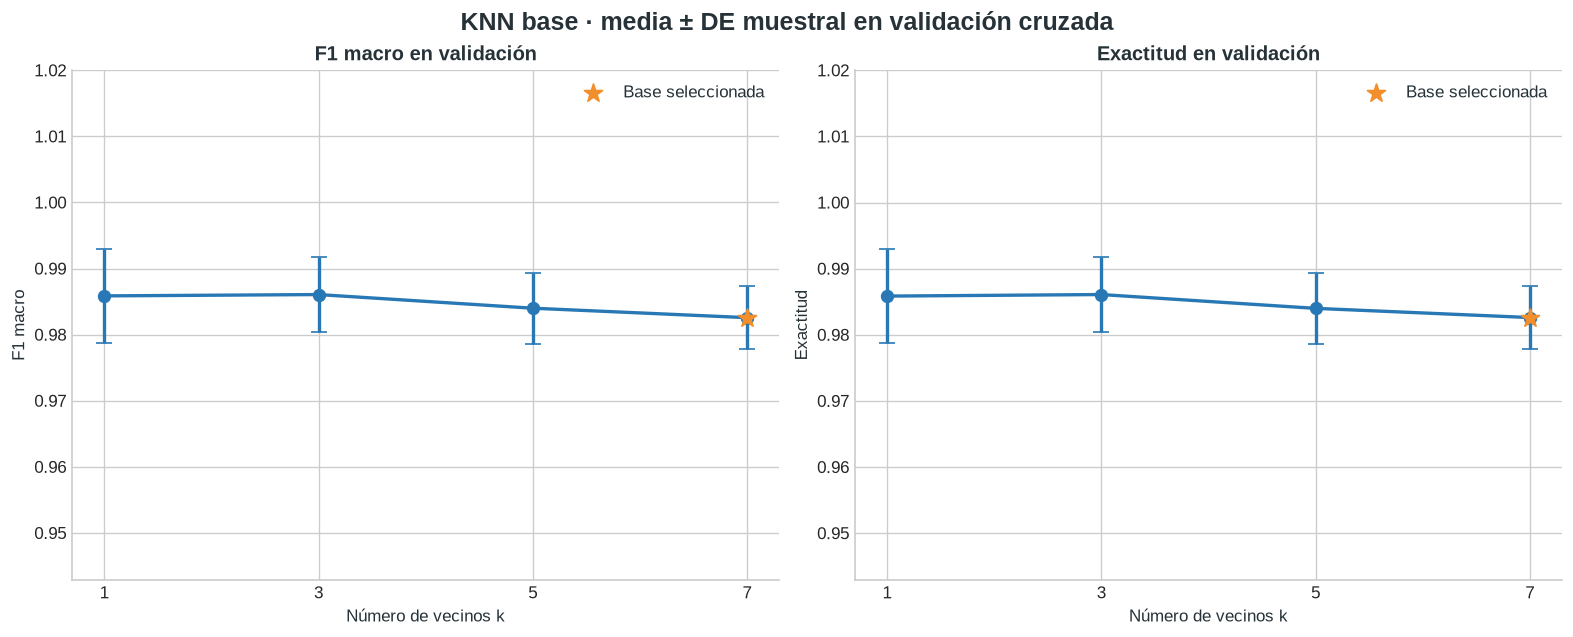

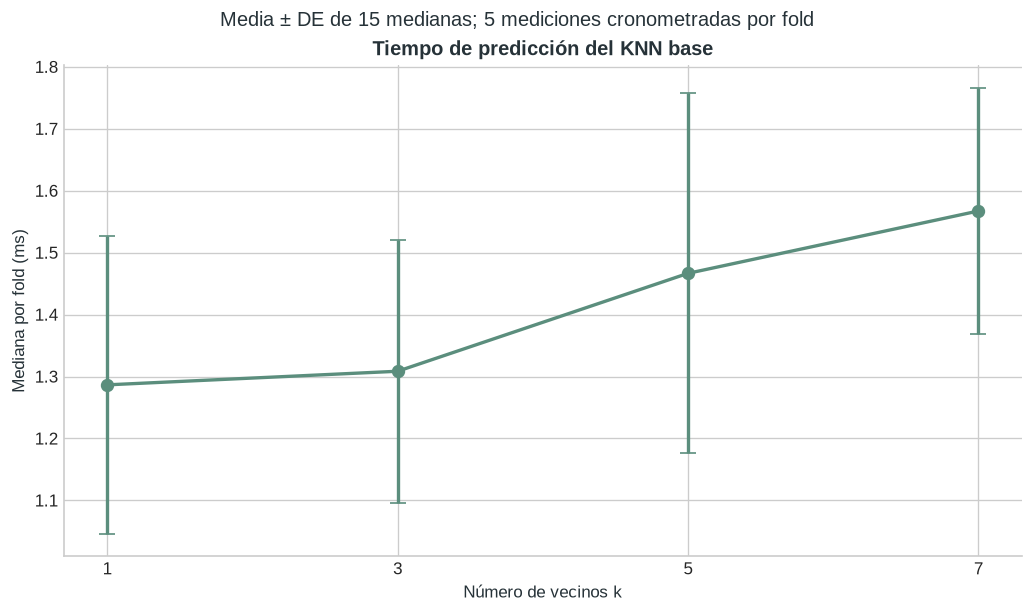

Figuras guardadas:
- report/plots/conteo_clases_split.png (61,305 bytes)
- report/plots/digits_ejemplos.png (40,748 bytes)
- report/plots/flujo_validacion.png (94,520 bytes)
- report/plots/knn_base_metricas_cv.png (105,302 bytes)
- report/plots/knn_base_tiempos_cv.png (66,516 bytes)
- report/plots/pca_knn_tradeoff_cv.png (180,891 bytes)
- report/plots/pca_scree_pair2.png (111,863 bytes)


In [18]:
k_axis = base_summary["k"].to_numpy()
selected_k = int(selected_base["k"])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
plot_specs = (
    ("f1_macro_validation", "F1 macro en validación", "F1 macro"),
    ("accuracy_validation", "Exactitud en validación", "Exactitud"),
)
for ax, (metric, title, ylabel) in zip(axes, plot_specs):
    means = base_summary[f"{metric}_mean"].to_numpy()
    stds = base_summary[f"{metric}_std"].to_numpy()
    ax.errorbar(k_axis, means, yerr=stds, fmt="o-", color="#2878B5", capsize=5, linewidth=2, markersize=7)
    ax.scatter([selected_k], [means[k_axis.tolist().index(selected_k)]], s=130, marker="*", color="#F28E2B", zorder=4, label="Base seleccionada")
    ax.set(title=title, xlabel="Número de vecinos k", ylabel=ylabel, xticks=k_axis)
    ax.set_ylim(max(0, float(np.min(means - stds)) - 0.035), min(1.02, float(np.max(means + stds)) + 0.035))
    ax.legend(frameon=False)
fig.suptitle("KNN base · media ± DE muestral en validación cruzada", fontsize=15, fontweight="bold")
fig.savefig(PLOTS_DIR / "knn_base_metricas_cv.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 5), constrained_layout=True)
time_means = base_summary["prediction_ms_median_mean"].to_numpy()
time_stds = base_summary["prediction_ms_median_std"].to_numpy()
ax.errorbar(k_axis, time_means, yerr=time_stds, fmt="o-", color="#5B8E7D", capsize=5, linewidth=2, markersize=7)
ax.set(title="Tiempo de predicción del KNN base", xlabel="Número de vecinos k", ylabel="Mediana por fold (ms)", xticks=k_axis)
fig.suptitle("Media ± DE de 15 medianas; 5 mediciones cronometradas por fold", fontsize=12)
fig.savefig(PLOTS_DIR / "knn_base_tiempos_cv.png", bbox_inches="tight")
plt.show()

print("Figuras guardadas:")
for plot_path in sorted(PLOTS_DIR.glob("*.png")):
    print(f"- {plot_path.relative_to(PROJECT_DIR)} ({plot_path.stat().st_size:,} bytes)")

## 6. Pareja 2: fundamento de PCA y reducción dimensional

PCA es una transformación lineal no supervisada: no utiliza `y`. Para cada fold, estima la media de cada atributo solo con el train y centra los datos, `Z = X_train - mu`. La matriz de covarianza muestral es

\[
S = \frac{Z^\top Z}{n-1},
\]

donde `n` es el número de ejemplos del train del fold. Los autovectores de `S` son direcciones ortogonales (`componentes principales`) y los autovalores ordenados `lambda_1 >= ... >= lambda_D` cuantifican la varianza en cada dirección. La proporción acumulada que retienen los primeros `d` componentes es

\[
V_d = \frac{\sum_{j=1}^{d}\lambda_j}{\sum_{j=1}^{D}\lambda_j}.
\]

Para el umbral `q`, PCA conserva el menor `d` tal que `V_d >= q`; se prueban `q ∈ {0.80, 0.90, 0.95}`. La transformación del ejemplo es `z W_d`. Con `whiten=False` no se escala cada componente por separado, por lo que se conserva su magnitud relativa al calcular distancias KNN.

La hipótesis —no una conclusión anticipada— es que una representación con menos dimensiones puede reducir ruido y acelerar KNN sin perder demasiada capacidad discriminativa. En cada fold se ajusta PCA **dentro del pipeline y solo sobre train**; validación únicamente se transforma. Así no se filtra información desde validación hacia los ejes principales.

,varianza objetivo,componentes en el train del fold ilustrativo
0,0.80,13
1,0.90,21
2,0.95,28


El scree plot es descriptivo; la dimensión usada por cada propuesta se estima de nuevo dentro de cada fold.


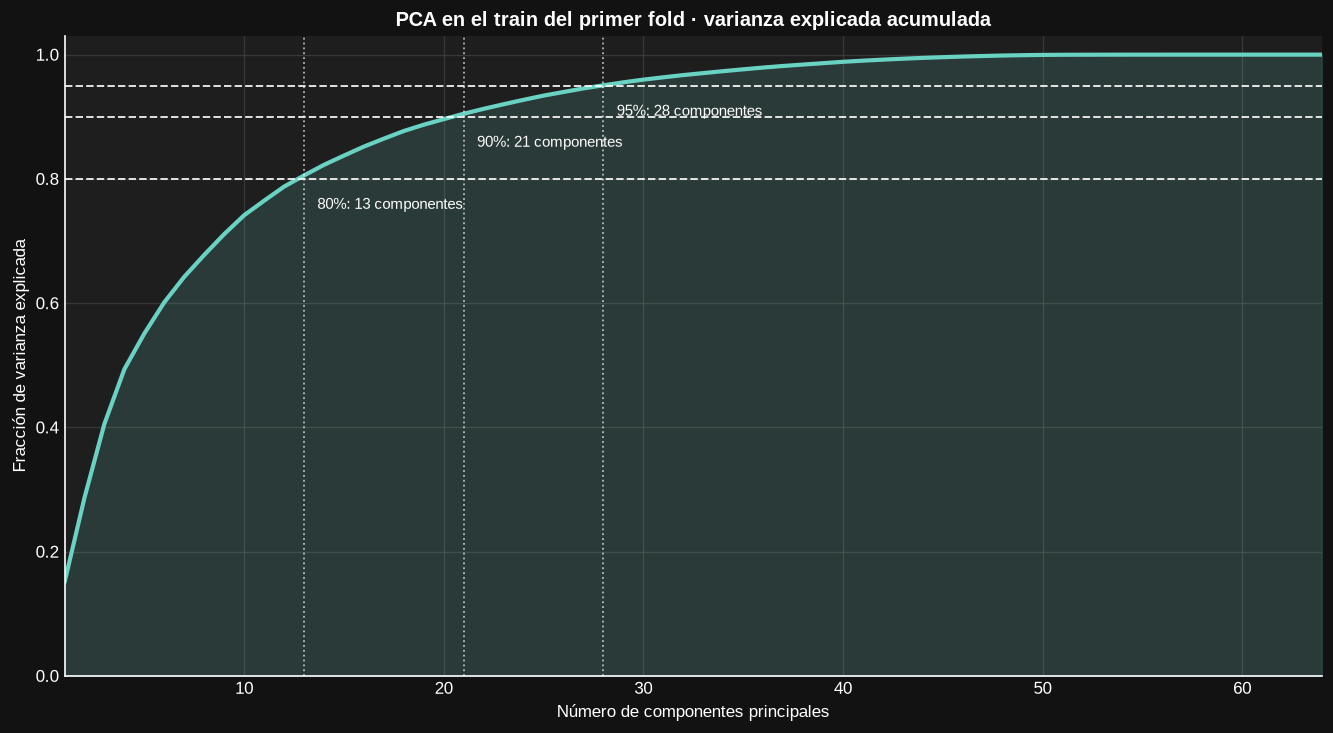

In [19]:
# Scree plot descriptivo: PCA se ajusta solo al train del primer fold, no a validación/test.
scree_train_positions, _ = cv_splits[0]
scree_pca = PCA(n_components=None, whiten=False, svd_solver="full")
scree_pca.fit(X_development[scree_train_positions])
cumulative_explained_variance = np.cumsum(scree_pca.explained_variance_ratio_)
scree_component_counts = {
    target: int(np.searchsorted(cumulative_explained_variance, target, side="left") + 1)
    for target in PCA_VARIANCE_TARGETS
}

scree_table = pd.DataFrame(
    {
        "varianza objetivo": list(scree_component_counts),
        "componentes en el train del fold ilustrativo": list(scree_component_counts.values()),
    }
)
display(scree_table)
print("El scree plot es descriptivo; la dimensión usada por cada propuesta se estima de nuevo dentro de cada fold.")

with plt.style.context("dark_background"):
    fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
    component_axis = np.arange(1, cumulative_explained_variance.size + 1)
    ax.plot(component_axis, cumulative_explained_variance, color="#69D2C3", linewidth=2.5)
    ax.fill_between(component_axis, cumulative_explained_variance, color="#69D2C3", alpha=0.16)
    ax.set_facecolor("#1e1e1e")
    fig.patch.set_facecolor("#121212")
    ax.set(
        title="PCA en el train del primer fold · varianza explicada acumulada",
        xlabel="Número de componentes principales",
        ylabel="Fracción de varianza explicada",
        ylim=(0, 1.03),
        xlim=(1, cumulative_explained_variance.size),
    )
    ax.grid(color="#444444", alpha=0.65)
    for target, component_count in scree_component_counts.items():
        ax.axhline(target, linestyle="--", linewidth=1.2, alpha=0.85)
        ax.axvline(component_count, linestyle=":", linewidth=1.1, alpha=0.65)
        ax.annotate(
            f"{target:.0%}: {component_count} componentes",
            xy=(component_count, target),
            xytext=(8, -18),
            textcoords="offset points",
            fontsize=9,
        )
    fig.savefig(PLOTS_DIR / "pca_scree_pair2.png", bbox_inches="tight")
    plt.show()

## 7. Pareja 2: grid PCA + KNN, diferencias pareadas y selección

Se recorren las 12 combinaciones `varianza objetivo × k`. Se conserva todo lo demás igual a la base: distancia euclidiana (`Minkowski p=2`), voto uniforme y búsqueda `brute`. `svd_solver="full"` hace determinista la descomposición; PCA no necesita semilla aleatoria en esta configuración. `whiten=False` preserva escalas relativas.

Por cada `(varianza objetivo, k, fold)` se registran F1 macro y exactitud de train/validación, `pca.n_components_` real, tamaños y cinco tiempos de predicción más la mediana. `n_components_` puede variar entre folds aunque el umbral de varianza sea fijo; por eso no se sustituye por una dimensión supuesta.

Para cada configuración, la diferencia se empareja con la línea base del **mismo `fold_id` y `k`**: `Delta F1 = F1 propuesta - F1 base` y análogamente para exactitud. Se resume la distribución de las 15 diferencias con media y DE muestral. No se reportan pruebas estadísticas ni valores p.

Regla para elegir la propuesta: (1) encontrar el máximo F1 macro medio en validación; (2) retener candidatas a no más de `Delta=0.005`; (3) menor dimensión media real entre folds; (4) menor DE de F1; (5) menor `k`. Si todavía hay empate exacto, se usa el umbral menor como desempate determinista documentado. La prueba reservada no interviene.

In [20]:
pca_fold_rows = []
for fold_number, ((train_positions, validation_positions), fold_info) in enumerate(
    zip(cv_splits, fold_records), start=1
):
    X_train_fold = X_development[train_positions]
    y_train_fold = y_development[train_positions]
    X_validation_fold = X_development[validation_positions]
    y_validation_fold = y_development[validation_positions]

    for variance_target in PCA_VARIANCE_TARGETS:
        for k in K_VALUES:
            # PCA y KNN viven en el mismo Pipeline para evitar ajustar PCA fuera del train fold.
            model = Pipeline(
                [
                    ("pca", PCA(n_components=variance_target, whiten=False, svd_solver="full")),
                    (
                        "knn",
                        KNeighborsClassifier(
                            n_neighbors=k,
                            metric="minkowski",
                            p=2,
                            weights="uniform",
                            algorithm="brute",
                        ),
                    ),
                ]
            )
            model.fit(X_train_fold, y_train_fold)
            train_predictions = model.predict(X_train_fold)
            validation_predictions = model.predict(X_validation_fold)
            timing_measurements_ms = measure_prediction_time_ms(model, X_validation_fold)

            pca_fold_rows.append(
                {
                    "fold_id": fold_info["fold_id"],
                    "repetition": fold_info["repetition"],
                    "fold_in_repetition": fold_info["fold_in_repetition"],
                    "family": "PCA+KNN",
                    "variance_target": variance_target,
                    "k": k,
                    "n_features_original": X_train_fold.shape[1],
                    "n_components_retained": int(model.named_steps["pca"].n_components_),
                    "n_train": y_train_fold.size,
                    "n_validation": y_validation_fold.size,
                    "f1_macro_train": f1_score(y_train_fold, train_predictions, average="macro", zero_division=0),
                    "accuracy_train": accuracy_score(y_train_fold, train_predictions),
                    "f1_macro_validation": f1_score(
                        y_validation_fold, validation_predictions, average="macro", zero_division=0
                    ),
                    "accuracy_validation": accuracy_score(y_validation_fold, validation_predictions),
                    "prediction_ms_median": float(np.median(timing_measurements_ms)),
                    **{
                        f"prediction_ms_measurement_{measurement_number}": timing
                        for measurement_number, timing in enumerate(timing_measurements_ms, start=1)
                    },
                }
            )

pca_fold_metrics = pd.DataFrame(pca_fold_rows)
expected_pca_evaluations = N_SPLITS * N_REPEATS * len(PCA_VARIANCE_TARGETS) * len(K_VALUES)
if len(pca_fold_metrics) != expected_pca_evaluations:
    raise AssertionError(f"Se esperaban {expected_pca_evaluations} evaluaciones PCA; se obtuvieron {len(pca_fold_metrics)}.")
if pca_fold_metrics["n_components_retained"].isna().any():
    raise AssertionError("Falta la dimensión PCA real de al menos un fold.")

PCA_FOLD_METRICS_PATH = PAIR2_RESULTS_DIR / "pca_fold_metrics.csv"
pca_fold_metrics.to_csv(PCA_FOLD_METRICS_PATH, index=False)

summary_metrics = (
    "f1_macro_train",
    "accuracy_train",
    "f1_macro_validation",
    "accuracy_validation",
    "n_components_retained",
    "prediction_ms_median",
)
pca_summary = (
    pca_fold_metrics.groupby(["variance_target", "k"], sort=True)[list(summary_metrics)]
    .agg(["mean", "std"])
)
pca_summary.columns = [f"{metric}_{statistic}" for metric, statistic in pca_summary.columns]
pca_summary = pca_summary.reset_index()

# Diferencias pareadas: una propuesta a la vez frente a la base del mismo k y los mismos 15 folds.
paired_difference_rows = []
for (variance_target, k), proposal_group in pca_fold_metrics.groupby(["variance_target", "k"], sort=True):
    baseline_group = fold_metrics.loc[fold_metrics["k"].eq(k)]
    fold_differences, _ = paired_difference_summary(proposal_group, baseline_group)
    fold_differences.insert(1, "variance_target", variance_target)
    paired_difference_rows.extend(fold_differences.to_dict(orient="records"))

pca_paired_differences = pd.DataFrame(paired_difference_rows)
PCA_PAIRED_PATH = PAIR2_RESULTS_DIR / "pca_paired_differences_by_fold.csv"
pca_paired_differences.to_csv(PCA_PAIRED_PATH, index=False)
pca_paired_summary = (
    pca_paired_differences.groupby(["variance_target", "k"], sort=True)[
        ["delta_f1_macro_validation", "delta_accuracy_validation"]
    ]
    .agg(["mean", "std"])
)
pca_paired_summary.columns = [f"{metric}_{statistic}" for metric, statistic in pca_paired_summary.columns]
pca_paired_summary = pca_paired_summary.reset_index()
PCA_PAIRED_SUMMARY_PATH = PAIR2_RESULTS_DIR / "pca_paired_difference_summary.csv"
pca_paired_summary.to_csv(PCA_PAIRED_SUMMARY_PATH, index=False)

# Selección descriptiva por F1 medio, margen, dimensión real media, DE y k.
max_pca_validation_f1 = pca_summary["f1_macro_validation_mean"].max()
pca_candidates = pca_summary.loc[
    max_pca_validation_f1 - pca_summary["f1_macro_validation_mean"] <= SELECTION_TOLERANCE
].copy()
pca_candidates = pca_candidates.sort_values(
    ["n_components_retained_mean", "f1_macro_validation_std", "k", "variance_target"],
    ascending=True,
    kind="stable",
)
selected_proposal = pca_candidates.iloc[0]
PCA_SUMMARY_PATH = PAIR2_RESULTS_DIR / "pca_summary.csv"
PCA_SELECTION_PATH = PAIR2_RESULTS_DIR / "selected_proposal.json"
pca_summary.to_csv(PCA_SUMMARY_PATH, index=False)
PCA_SELECTION_PATH.write_text(
    json.dumps(
        {
            "selected_family": "PCA+KNN",
            "selected_variance_target": float(selected_proposal["variance_target"]),
            "selected_k": int(selected_proposal["k"]),
            "mean_retained_components": float(selected_proposal["n_components_retained_mean"]),
            "mean_validation_macro_f1": float(selected_proposal["f1_macro_validation_mean"]),
            "std_validation_macro_f1": float(selected_proposal["f1_macro_validation_std"]),
            "selection_tolerance": SELECTION_TOLERANCE,
            "tie_breaking": [
                "lower mean number of components retained across folds",
                "lower sample SD of validation macro F1",
                "lower k",
                "lower variance target for an exact remaining tie",
            ],
            "test_used_for_selection": False,
        },
        indent=2,
    ),
    encoding="utf-8",
)

# Presentar todas las propuestas con media ± DE; DE usa los 15 folds (ddof=1).
summary_display = pca_summary.copy()
for metric in summary_metrics:
    summary_display[metric] = summary_display.apply(
        lambda row, name=metric: f"{row[f'{name}_mean']:.4f} ± {row[f'{name}_std']:.4f}", axis=1
    )
display(
    summary_display[["variance_target", "k", *summary_metrics]].rename(
        columns={
            "variance_target": "Varianza objetivo",
            "k": "k",
            "f1_macro_train": "F1 macro train (media ± DE)",
            "accuracy_train": "Exactitud train (media ± DE)",
            "f1_macro_validation": "F1 macro validación (media ± DE)",
            "accuracy_validation": "Exactitud validación (media ± DE)",
            "n_components_retained": "Componentes retenidos (media ± DE)",
            "prediction_ms_median": "Predicción validación ms (media ± DE)",
        }
    )
)
display(
    pca_paired_summary.rename(
        columns={
            "variance_target": "Varianza objetivo",
            "k": "k",
            "delta_f1_macro_validation_mean": "Delta F1 macro (media)",
            "delta_f1_macro_validation_std": "Delta F1 macro (DE)",
            "delta_accuracy_validation_mean": "Delta exactitud (media)",
            "delta_accuracy_validation_std": "Delta exactitud (DE)",
        }
    ).style.format(precision=4)
)
print(f"Evaluaciones PCA+KNN: {len(pca_fold_metrics)} (= 12 configuraciones × 15 folds)")
print(f"Dimensiones retenidas observadas: {sorted(pca_fold_metrics['n_components_retained'].unique().tolist())}")
print(
    f"Propuesta seleccionada: varianza={selected_proposal['variance_target']:.0%}, "
    f"k={int(selected_proposal['k'])}, D medio={selected_proposal['n_components_retained_mean']:.2f}, "
    f"F1 macro validación={selected_proposal['f1_macro_validation_mean']:.4f} ± "
    f"{selected_proposal['f1_macro_validation_std']:.4f}."
)
print(f"Filas por fold: {PCA_FOLD_METRICS_PATH}")
print(f"Resumen y selección: {PCA_SUMMARY_PATH}; {PCA_SELECTION_PATH}")
print(f"Diferencias pareadas: {PCA_PAIRED_PATH}; {PCA_PAIRED_SUMMARY_PATH}")

,Varianza objetivo,k,F1 macro train (media ± DE),Exactitud train (media ± DE),F1 macro validación (media ± DE),Exactitud validación (media ± DE),Componentes retenidos (media ± DE),Predicción validación ms (media ± DE)
0,0.80,1,1.0000 ± 0.0000,1.0000 ± 0.0000,0.9802 ± 0.0058,0.9803 ± 0.0058,13.0000 ± 0.0000,1.2050 ± 0.1694
1,0.80,3,0.9894 ± 0.0018,0.9894 ± 0.0018,0.9786 ± 0.0076,0.9787 ± 0.0075,13.0000 ± 0.0000,1.3526 ± 0.3592
2,0.80,5,0.9877 ± 0.0018,0.9878 ± 0.0018,0.9785 ± 0.0079,0.9787 ± 0.0079,13.0000 ± 0.0000,1.3130 ± 0.1694
3,0.80,7,0.9860 ± 0.0017,0.9861 ± 0.0017,0.9774 ± 0.0056,0.9775 ± 0.0055,13.0000 ± 0.0000,1.4089 ± 0.2026
4,0.90,1,1.0000 ± 0.0000,1.0000 ± 0.0000,0.9858 ± 0.0065,0.9858 ± 0.0065,21.0000 ± 0.0000,1.1755 ± 0.1384
5,0.90,3,0.9926 ± 0.0017,0.9926 ± 0.0017,0.9839 ± 0.0064,0.9840 ± 0.0064,21.0000 ± 0.0000,1.2341 ± 0.1830
6,0.90,5,0.9898 ± 0.0021,0.9899 ± 0.0021,0.9837 ± 0.0052,0.9838 ± 0.0052,21.0000 ± 0.0000,1.3909 ± 0.1352
7,0.90,7,0.9870 ± 0.0020,0.9870 ± 0.0020,0.9805 ± 0.0054,0.9805 ± 0.0054,21.0000 ± 0.0000,1.4398 ± 0.1195
8,0.95,1,1.0000 ± 0.0000,1.0000 ± 0.0000,0.9868 ± 0.0060,0.9868 ± 0.0061,28.0000 ± 0.0000,1.2903 ± 0.1645
9,0.95,3,0.9929 ± 0.0019,0.9929 ± 0.0019,0.9858 ± 0.0063,0.9858 ± 0.0064,28.0000 ± 0.0000,1.2599 ± 0.1119


,Varianza objetivo,k,Delta F1 macro (media),Delta F1 macro (DE),Delta exactitud (media),Delta exactitud (DE)
0,0.8000,1,-0.0057,0.0053,-0.0056,0.0052
1,0.8000,3,-0.0075,0.0044,-0.0074,0.0043
2,0.8000,5,-0.0055,0.0075,-0.0053,0.0074
3,0.8000,7,-0.0052,0.0056,-0.0051,0.0056
4,0.9000,1,-0.0001,0.0043,-0.0000,0.0044
5,0.9000,3,-0.0021,0.0042,-0.0021,0.0041
6,0.9000,5,-0.0003,0.0040,-0.0002,0.0040
7,0.9000,7,-0.0021,0.0030,-0.0021,0.0029
8,0.9500,1,0.0009,0.0031,0.0009,0.0031
9,0.9500,3,-0.0002,0.0039,-0.0002,0.0038


Evaluaciones PCA+KNN: 180 (= 12 configuraciones × 15 folds)
Dimensiones retenidas observadas: [13, 21, 28]
Propuesta seleccionada: varianza=90%, k=5, D medio=21.00, F1 macro validación=0.9837 ± 0.0052.
Filas por fold: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_2/pca_fold_metrics.csv
Resumen y selección: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_2/pca_summary.csv; /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_2/selected_proposal.json
Diferencias pareadas: /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_2/pca_paired_differences_by_fold.csv; /home/ldan/Documents/0_uni/5to_sem/ml_team/practicas/p_03/results/pareja_2/pca_paired_difference_summary.csv


## 8. Comparación visual de las propuestas PCA

En el gráfico de la izquierda, cada punto representa una configuración PCA+KNN: el eje horizontal muestra el número medio real de componentes retenidos y el vertical el F1 macro medio de validación. Barras horizontales y verticales representan ±1 DE entre folds. Color identifica el umbral de varianza; marcador distingue `k`. La estrella compara la base seleccionada (64 atributos) y la propuesta seleccionada. El gráfico de la derecha relaciona tiempo de predicción y F1; el tiempo es la media ± DE de las medianas por fold. Estas gráficas son descriptivas: no son intervalos de confianza ni evidencia inferencial.

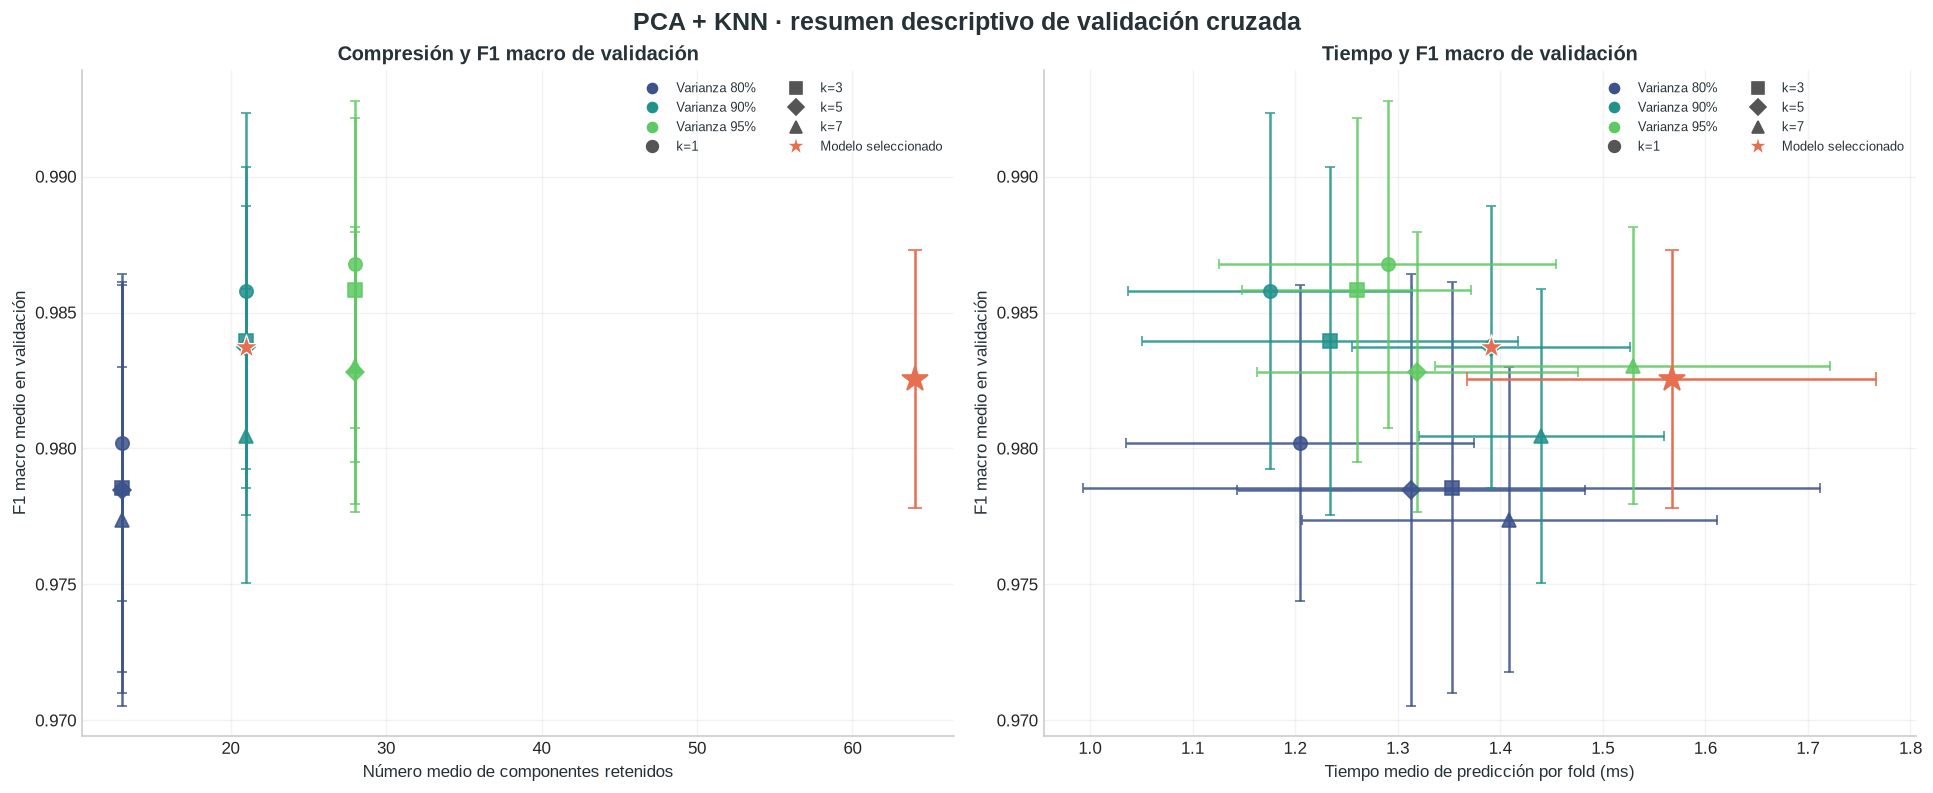

Gráficas de pareja 2 guardadas:
- report/plots/pca_scree_pair2.png (111,863 bytes)
- report/plots/pca_knn_tradeoff_cv.png (183,306 bytes)


In [21]:
variance_palette = dict(
    zip(PCA_VARIANCE_TARGETS, sns.color_palette("viridis", n_colors=len(PCA_VARIANCE_TARGETS)))
)
k_markers = {1: "o", 3: "s", 5: "D", 7: "^"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), constrained_layout=True)

for ax, x_mean_metric, x_std_metric, xlabel, title in (
    (
        axes[0],
        "n_components_retained_mean",
        "n_components_retained_std",
        "Número medio de componentes retenidos",
        "Compresión y F1 macro de validación",
    ),
    (
        axes[1],
        "prediction_ms_median_mean",
        "prediction_ms_median_std",
        "Tiempo medio de predicción por fold (ms)",
        "Tiempo y F1 macro de validación",
    ),
):
    for variance_target in PCA_VARIANCE_TARGETS:
        subset = pca_summary.loc[pca_summary["variance_target"].eq(variance_target)]
        for _, row in subset.iterrows():
            ax.errorbar(
                row[x_mean_metric],
                row["f1_macro_validation_mean"],
                xerr=row[x_std_metric],
                yerr=row["f1_macro_validation_std"],
                fmt=k_markers[int(row["k"])],
                color=variance_palette[variance_target],
                markersize=8,
                capsize=3,
                alpha=0.86,
            )
    ax.set(title=title, xlabel=xlabel, ylabel="F1 macro medio en validación")
    ax.grid(alpha=0.25)

base_selected = base_summary.loc[base_summary["k"].eq(int(selected_base["k"]))].iloc[0]
axes[0].errorbar(
    int(base_selected["n_features"]),
    base_selected["f1_macro_validation_mean"],
    yerr=base_selected["f1_macro_validation_std"],
    fmt="*",
    color="#E76F51",
    markersize=16,
    capsize=4,
    label="KNN base seleccionada",
    zorder=5,
)
axes[1].errorbar(
    base_selected["prediction_ms_median_mean"],
    base_selected["f1_macro_validation_mean"],
    xerr=base_selected["prediction_ms_median_std"],
    yerr=base_selected["f1_macro_validation_std"],
    fmt="*",
    color="#E76F51",
    markersize=16,
    capsize=4,
    label="KNN base seleccionada",
    zorder=5,
)
selected_x = float(selected_proposal["n_components_retained_mean"])
selected_y = float(selected_proposal["f1_macro_validation_mean"])
selected_time = float(selected_proposal["prediction_ms_median_mean"])
axes[0].scatter([selected_x], [selected_y], marker="*", s=230, color="#E76F51", edgecolor="white", linewidth=0.8, label="PCA+KNN seleccionada", zorder=6)
axes[1].scatter([selected_time], [selected_y], marker="*", s=230, color="#E76F51", edgecolor="white", linewidth=0.8, label="PCA+KNN seleccionada", zorder=6)

legend_handles = [
    plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=variance_palette[target], markersize=8, label=f"Varianza {target:.0%}")
    for target in PCA_VARIANCE_TARGETS
]
legend_handles.extend(
    plt.Line2D([0], [0], marker=marker, color="#555555", linestyle="None", markersize=7, label=f"k={k}")
    for k, marker in k_markers.items()
)
legend_handles.extend(
    [
        plt.Line2D([0], [0], marker="*", color="w", markerfacecolor="#E76F51", markersize=13, label="Modelo seleccionado"),
    ]
)
for ax in axes:
    ax.legend(handles=legend_handles, frameon=False, fontsize=8, ncol=2)
fig.suptitle("PCA + KNN · resumen descriptivo de validación cruzada", fontsize=15, fontweight="bold")
fig.savefig(PLOTS_DIR / "pca_knn_tradeoff_cv.png", bbox_inches="tight")
plt.show()

print("Gráficas de pareja 2 guardadas:")
for plot_path in (PLOTS_DIR / "pca_scree_pair2.png", PLOTS_DIR / "pca_knn_tradeoff_cv.png"):
    print(f"- {plot_path.relative_to(PROJECT_DIR)} ({plot_path.stat().st_size:,} bytes)")

## 9. Interpretación integrada y entrega para pareja 3

### Lectura de resultados y límites

Las tablas reportan medias ± DE muestral de las evaluaciones de validación; la DE describe variabilidad entre folds, no significancia. La diferencia pareada compara cada variante PCA con la base del mismo `k` y fold. La configuración seleccionada por validación puede tener una media optimista porque participó en la selección. La prueba reservada aporta la comprobación final y **no se ha evaluado en este notebook**.

La selección base se hace solo dentro de la familia base; la selección de propuesta solo dentro de PCA+KNN. En ambos casos se usa el margen `Delta≤0.005` según README; para PCA, la dimensión es el promedio de `n_components_` real a través de los 15 folds. Los resultados son descriptivos: no se aplican pruebas estadísticas ni se afirman equivalencia o superioridad general.

### Archivos persistidos

- `results/pareja_1/indices.json`: split 80/20 y posiciones e índices originales de los 15 folds; es el contrato compartido para todas las parejas.
- `results/pareja_1/base_fold_metrics.csv`, `base_summary.csv` y `selected_base.json`: línea base, métricas y selección.
- `results/pareja_2/pca_fold_metrics.csv`: 180 filas (12 configuraciones × 15 folds), train/validación, dimensión real por fold y tiempos.
- `results/pareja_2/pca_summary.csv` y `selected_proposal.json`: medias ± DE y selección PCA+KNN.
- `results/pareja_2/pca_paired_differences_by_fold.csv` y `pca_paired_difference_summary.csv`: diferencias propuesta − base, fold a fold, y resumen descriptivo.
- `report/plots/`: figuras de distribución, protocolo, KNN base, scree PCA y compromiso dimensiones/tiempo/F1.

### Lo que sigue para pareja 3

1. Leer `indices.json`, `selected_base.json` y `selected_proposal.json`; usar los índices originales de desarrollo y prueba ya guardados.
2. Reentrenar la mejor configuración base y la propuesta con todo desarrollo (80 %). Para PCA, ajustar el pipeline completo con el umbral seleccionado solo sobre desarrollo.
3. Evaluar ambos modelos en el 20 % de prueba **una sola vez**. Reportar métricas puntuales, dimensiones, matrices de confusión y tiempos; no añadir DE a una evaluación única.
4. No ajustar, reseleccionar ni cambiar parámetros después de consultar el test. Las medias de validación pueden ser optimistas porque participaron en selección.

**Parámetros fijados/no explorados:** no se optimizaron la escala, semilla, partición, folds, métrica euclidiana, voto `weights="distance"` ni `algorithm="kd_tree"`; se mantuvieron constantes para comparar familias bajo el protocolo acordado.

### Advertencia obligatoria para el informe/presentación

> «Este análisis es meramente descriptivo y no cuenta con apoyo inferencial. Las medias y desviaciones estándar resumen las evaluaciones realizadas; no demuestran diferencias estadísticamente significativas, equivalencia ni superioridad general».
